# Activity: Can We Trust the AI Analyst? — FreshKart Case

**Unit 4 · AI-Assisted Visualization · LLMs for EDA & Human-in-the-Loop Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

**FreshKart** is a quick-commerce grocery chain with **10 dark stores in 3 cities** (Bengaluru, Pune, Hyderabad). Operations head **Meera** has a leadership meeting tomorrow. She asked an AI analytics assistant:

> *"Summarise our business from January to September and tell me what went wrong in September."*

The assistant has produced the report below. **You are the analyst.** Meera will present whatever you sign off, so your job is to **verify, correct or reject** each AI insight using the data, and to say *why*.

**Ground rules (from the lecture):** every number must come from code you can inspect · an alert tells you where to look, a chart tells you what is true · the AI proposes, the human decides.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_orders.csv` (synthetic)

| Column | Meaning |
|---|---|
| `order_id` | unique order reference |
| `order_date` | date of order |
| `city`, `store_id` | where the order was fulfilled |
| `zone` | `Urban` or `Suburban` delivery address |
| `delivery_partner` | `Partner A` or `Partner B` |
| `items`, `discount_pct`, `order_value` | basket size, discount applied, bill value (₹) |
| `distance_km`, `delivery_minutes`, `on_time` | delivery distance, time taken, 1 if ≤ 30 min |
| `rating` | customer rating 1–5 (blank if not given) |
| `app_sessions_7d`, `loyalty_points` | customer app activity and loyalty balance |

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_orders.csv", parse_dates=["order_date"])
df.head()

,order_id,order_date,city,store_id,zone,delivery_partner,items,discount_pct,order_value,distance_km,delivery_minutes,on_time,rating,app_sessions_7d,loyalty_points
0,FK100000,2026-01-01,Bengaluru,B1,Urban,Partner A,4,15,300,3.2,22,1,NaN,6,281
1,FK100001,2026-01-01,Bengaluru,B1,Urban,Partner A,3,5,187,1.8,16,1,4.0,4,299
2,FK100002,2026-01-01,Bengaluru,B1,Suburban,Partner A,2,20,244,2.7,28,1,3.0,8,387
3,FK100003,2026-01-01,Bengaluru,B1,Urban,Partner B,7,20,1223,1.4,20,1,4.0,8,234
4,FK100004,2026-01-01,Bengaluru,B1,Urban,Partner B,6,5,1156,3.5,28,1,5.0,11,226


## The AI assistant's report (to be validated)

| # | Insight type | AI statement |
|---|---|---|
| 1 | Trend | "Bengaluru orders grew steadily from January to September, by about **+56 orders per month**." |
| 2 | Distribution | "The **average order value is ₹465**." |
| 3 | Comparison | "Pune orders **more than doubled** from Q2 to Q3 (**+117%**), so the Pune expansion is a huge success." |
| 4 | Comparison | "Hyderabad orders **fell 28%** in September compared with August, **because delivery service there got worse**." |
| 5 | Comparison | "**Partner B is more punctual than Partner A** (93% vs 87% on time), so we should route all orders to Partner B." |
| 6 | Correlation | "Longer delivery times go with lower ratings (**r = −0.32** among rated orders)." |
| 7 | Correlation | "Bigger discounts and bigger baskets move together (**r = 0.38**)." |
| 8 | Comparison | "Suburban orders take about **5 minutes longer** to deliver than urban orders." |
| 9 | Prediction | "**Orders will recover in October.**" |

---
## Part 1 · Is the data trustworthy? Profile before you believe

An AI narrates a profile, so a flawed profile gives a confident but flawed story. Compute the basics yourself.

In [2]:
profile = {
    "rows": len(df),
    "columns": df.shape[1],
    "duplicate_rows": int(df.duplicated().sum()),
    "rating_missing_pct": round(df["rating"].isna().mean() * 100, 1),
    "order_id_unique_pct": round(df["order_id"].nunique() / len(df) * 100, 1),
}
profile

{'rows': 13987,
 'columns': 15,
 'duplicate_rows': 70,
 'rating_missing_pct': np.float64(27.6),
 'order_id_unique_pct': 99.5}

mean = ₹465 | median = ₹358 | skew = 13.2


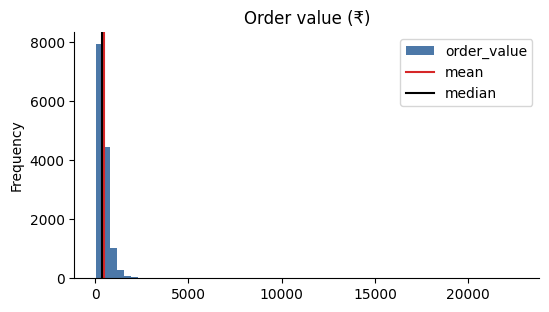

In [3]:
# From here on we work with the cleaned table (duplicates removed).
df = df.drop_duplicates().copy()

aov_mean = df["order_value"].mean()
aov_median = df["order_value"].median()
aov_skew = round(stats.skew(df["order_value"]), 1)

if ready(aov_mean, aov_median):
    print(f"mean = ₹{aov_mean:.0f} | median = ₹{aov_median:.0f} | skew = {aov_skew}")
    df["order_value"].plot.hist(bins=60, color="#4c78a8", title="Order value (₹)")
    plt.axvline(aov_mean, color="#d62728", label="mean"); plt.axvline(aov_median, color="black", label="median")
    plt.legend(); plt.show()

In [4]:
# Where are the ratings missing?
df.groupby("city")["rating"].apply(lambda s: s.isna().mean() * 100).round(1)

city
Bengaluru    21.1
Hyderabad    45.0
Pune         20.6
Name: rating, dtype: float64

**✏️ Your answer (Part 1):**
(a) Which AI insight(s) are affected by what you just found about the *average*, and how should the statement be rewritten?
(b) Insight 6 uses ratings. What risk does the missing-rating pattern create?

*Your answer:*

**(a)** Insight 2 is affected. The mean (₹465) is arithmetically correct, but order value is heavily right-skewed (skew ≈ 13.2): a few very large baskets pull the mean far above the typical order. The **median is ₹358**, so "average" overstates what a normal customer spends by about ₹107. Also, the profile found **70 fully duplicated rows** (order_id only 99.5% unique), so every figure must be computed after de-duplication. Rewrite: *"The typical (median) order is ₹358. The mean is ₹465 because a small number of very large orders pull it up."* Insights 3, 4 and 9 also rest on order counts, so they are affected by the duplicates as well.

**(b)** 27.6% of ratings are missing, and the gaps are uneven: **45% in Hyderabad** against about 21% in Bengaluru and Pune, and more often missing on slow deliveries (about 35% for deliveries over 40 min, against about 27% for fast ones). The r = −0.32 is computed only on customers who chose to rate, so it is a biased sample (not missing at random). It under-represents Hyderabad and the slowest, probably angriest, deliveries. The true relationship could be stronger or different, and the statement does not hold for all customers.

---
## Part 2 · Defaults shape the story: bin width

The assistant looked at a 1-minute-bin histogram of one store's deliveries and wrote: *"Delivery times are **multimodal**, with three separate peaks."* Look at the same 150 orders with different bin widths.

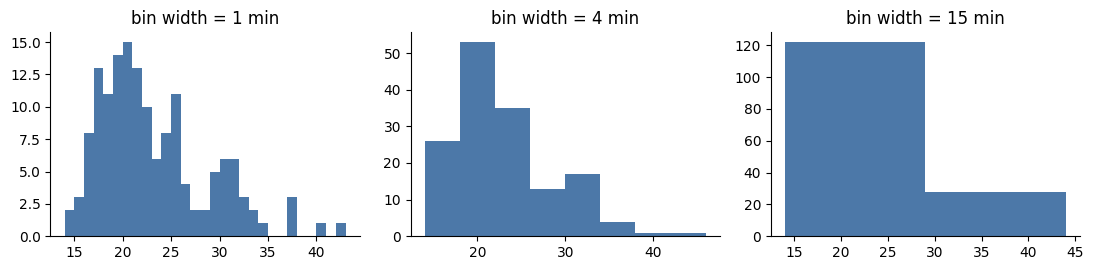

multimodal supported? False | best bin width = 4 min


In [5]:
sample = df[df.store_id == "B3"].sample(150, random_state=1)["delivery_minutes"]
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8))
for ax, w in zip(axes, [1, 4, 15]):
    ax.hist(sample, bins=np.arange(sample.min(), sample.max() + w, w), color="#4c78a8")
    ax.set_title(f"bin width = {w} min")
plt.tight_layout(); plt.show()

multimodal_supported = False   # the 'peaks' at 1-min bins are noise; 4- and 15-min bins show one peak with a right tail
best_bin_width = 4
print(f"multimodal supported? {multimodal_supported} | best bin width = {best_bin_width} min")

**✏️ Your answer (Part 2):** In one sentence, what should the analyst do before accepting a shape claim from an automated report?

*Your answer:*

Re-draw the distribution at several bin widths (or use a KDE or rug plot) and only accept a shape claim such as "multimodal" if it holds across sensible widths. At 1-minute bins with n = 150 the "peaks" are sampling noise. At 4 minutes the distribution has a single peak around 18–22 min with a right tail, and 15 minutes is too coarse to show any shape.

---
## Part 3 · Trends, correlations and patterns

### 3a · Trend (insight 1)

slope = 56.2 orders/month | Kendall tau = 0.89, p = 0.0002


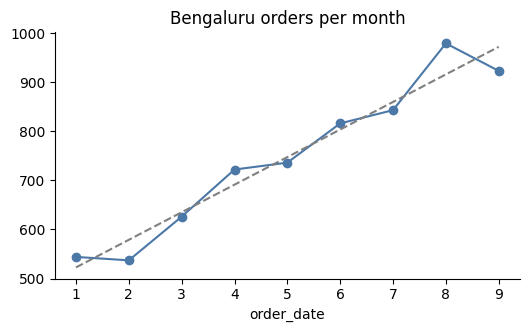

In [6]:
bengaluru = df[df.city == "Bengaluru"]
monthly = bengaluru.groupby(bengaluru["order_date"].dt.month).size()
months = monthly.index.values

slope = np.polyfit(months, monthly.values, 1)[0]
tau, p_trend = stats.kendalltau(months, monthly.values)    # Mann–Kendall-style trend test

if ready(slope):
    print(f"slope = {slope:.1f} orders/month | Kendall tau = {tau:.2f}, p = {p_trend:.4f}")
    ax = monthly.plot(marker="o", color="#4c78a8", title="Bengaluru orders per month")
    ax.plot(months, np.polyval(np.polyfit(months, monthly.values, 1), months), "--", color="grey")
    plt.show()

### 3b · Correlation (insights 6 and 7)

discount~items r = 0.38 | minutes~rating r = -0.316 | hours~rating r = -0.316


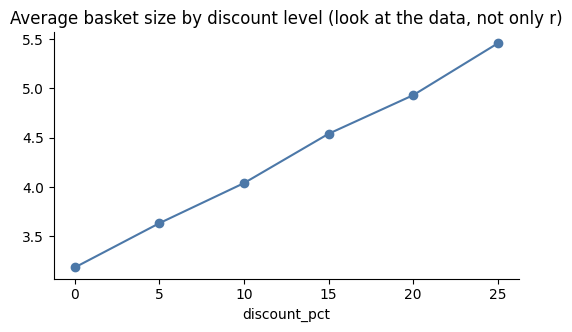

In [7]:
r_disc_items = df["discount_pct"].corr(df["items"])

# Same question, different units: minutes -> hours
rated = df.dropna(subset=["rating"]).copy()
rated["delivery_hours"] = rated["delivery_minutes"] / 60
r_minutes = rated["delivery_minutes"].corr(rated["rating"])
r_hours = rated["delivery_hours"].corr(rated["rating"])
r_unchanged = bool(np.isclose(r_minutes, r_hours))

if ready(r_disc_items, r_unchanged):
    print(f"discount~items r = {r_disc_items:.2f} | minutes~rating r = {r_minutes:.3f} | hours~rating r = {r_hours:.3f}")
    df.groupby("discount_pct")["items"].mean().plot(marker="o", color="#4c78a8",
        title="Average basket size by discount level (look at the data, not only r)")
    plt.show()

### 3c · Scanning many pairs

The assistant also scanned **every pair** of the 7 numeric columns below and flags any pair with p < 0.05 as a "finding".

In [8]:
num_cols = ["order_value", "items", "discount_pct", "distance_km", "delivery_minutes", "app_sessions_7d", "loyalty_points"]

n_pairs = len(num_cols) * (len(num_cols) - 1) // 2
expected_false = n_pairs * 0.05
bonferroni = 0.05 / n_pairs

rows = []
for a, b in itertools.combinations(num_cols, 2):
    r, p = stats.pearsonr(df[a], df[b])
    rows.append((a, b, round(r, 3), p))
scan = pd.DataFrame(rows, columns=["x", "y", "r", "p"]).sort_values("p")

if ready(n_pairs, expected_false, bonferroni):
    print(f"pairs = {n_pairs} | expected false positives = {expected_false:.2f} | Bonferroni threshold = {bonferroni:.4f}")
    flagged = scan[scan["p"] < 0.05].copy()
    flagged["survives_bonferroni"] = flagged["p"] < bonferroni
    display(flagged)

pairs = 21 | expected false positives = 1.05 | Bonferroni threshold = 0.0024


,x,y,r,p,survives_bonferroni
0,order_value,items,0.325,0.000000e+00,True
6,items,discount_pct,0.378,0.000000e+00,True
15,distance_km,delivery_minutes,0.748,0.000000e+00,True
1,order_value,discount_pct,0.066,5.802888e-15,True
14,discount_pct,loyalty_points,-0.022,8.317915e-03,False


**✏️ Your answer (3a–3c):**
(a) Insight 1 rests on 9 monthly points. Is the trend claim reasonable, and what would you show with it?
(b) Insight 7 says discounts and baskets "move together". Does the chart support the wording, and can the AI say discounts *cause* bigger baskets?
(c) Look at the flagged table. Which pair is most likely a false alarm, and what are **two** reasons you say so?

*Your answer:*

**(a)** Reasonable. The slope is +56.2 orders/month, and Kendall's τ = 0.89 (p = 0.0002) shows a strong monotonic rise. Only August to September dips (979 → 923), so "steadily" is slightly generous. With only 9 points, I would show the monthly line chart with the fitted line and the actual values (544 → 923), point out the September dip, and say it is 9 months of data, not a long-run trend. I would not extrapolate from it.

**(b)** Yes, on wording: r = 0.38, and the chart shows average basket size rising steadily from about 3.2 items at 0% discount to about 5.5 at 25%, so "move together" is fair. No, on causation: this is observational data. Discounts may be offered *on* bigger baskets (for example, threshold offers such as "10% off above 5 items"), or both may be driven by a third factor such as promotion days or loyal customers. Saying discounts *cause* bigger baskets would need an experiment, for example an A/B test of discount levels.

**(c)** The most likely false alarm is **discount_pct ~ loyalty_points** (r = −0.022, p = 0.008). Reasons: (1) it does **not survive the Bonferroni correction** (0.05/21 = 0.0024). With 21 pairs we expect about 1.05 "significant" pairs by chance alone, and this is exactly the borderline one. (2) The **effect size is negligible**: r = −0.02 means loyalty points explain about 0.05% of the variance in discount. It is "significant" only because n ≈ 14,000 makes tiny effects pass a p-value test. (3) There is no plausible business mechanism linking them. order_value ~ discount_pct (r = 0.066) survives Bonferroni but is also too small to matter in practice.

### 3d · Patterns: grouping the stores

The assistant ran **PCA + k-means (k = 3)** on store-level features and proposed three store "segments".

C:\Users\Chinmayi Hebbar A M\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Chinmayi Hebbar A M\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Chinmayi Hebbar A M\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Chinmayi Hebbar A M\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._e

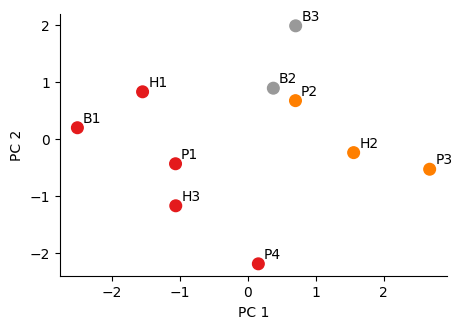

,segment,orders_per_active_day,on_time,suburban_share
store_id,,,,
B1,0,8.29,0.92,0.35
H1,0,4.99,0.91,0.35
P1,0,4.76,0.90,0.37
H3,0,4.30,0.91,0.39
P4,0,4.34,0.88,0.41
H2,1,5.24,0.89,0.45
P3,1,5.25,0.88,0.48
P2,1,4.39,0.91,0.42
B2,2,8.90,0.90,0.45


In [9]:
d = df.assign(month=df["order_date"].dt.month)
store = df.groupby("store_id").agg(
    orders=("order_id", "count"),
    median_value=("order_value", "median"),
    on_time=("on_time", "mean"),
    suburban_share=("zone", lambda s: (s == "Suburban").mean()),
    avg_discount=("discount_pct", "mean"),
    active_days=("order_date", "nunique"),
)
store["orders_per_active_day"] = store["orders"] / store["active_days"]
feats = store.drop(columns=["orders", "active_days"])

Z = StandardScaler().fit_transform(feats)
pcs = PCA(n_components=2).fit_transform(Z)
store["segment"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.scatter(pcs[:, 0], pcs[:, 1], c=store["segment"], cmap="Set1", s=70)
for sid, (x, y) in zip(store.index, pcs):
    ax.annotate(sid, (x, y), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); plt.show()
store[["segment", "orders_per_active_day", "on_time", "suburban_share"]].round(2).sort_values("segment")

**✏️ Your answer (3d):** The AI says these are three meaningful store "types". With only 10 stores, what is one reason a human should hesitate, and what would you check before naming the segments?

*Your answer:*

With only 10 stores, k-means will always return 3 groups, even if none exist, and moving one store can reshape a cluster. There is no hold-out and no stability, so the segments are a description of 10 points, not discovered "types". The result also looks incoherent: segment 0 puts **B1 (8.3 orders/day)** with P1, H3 and P4 (about 4.3–5 orders/day), while the similar B2 and B3 form their own segment. Two of the inputs are also distorted by data problems: P3 and P4 opened only in Q3, and H2 has a 3-week gap.

Before naming segments I would check: the raw feature table and pairwise scatter plots (do the groups visibly separate?); silhouette scores for k = 2–4; stability under different random seeds and leave-one-store-out; the PCA loadings (what PC1 and PC2 mean); and whether the grouping simply reproduces city or store age. Only then would I give business names, and I would confirm them with the operations team.

---
## Part 4 · From an observation to hypotheses (insight 4)

**Observation:** Hyderabad orders fell sharply in September. The AI jumped straight to "service got worse". A better assistant would list *competing* hypotheses and the evidence that separates them:

| | Hypothesis | Test |
|---|---|---|
| A | Delivery service got worse | on-time % in Aug vs Sep |
| B | A data problem: some store has missing rows | rows per store per week |
| C | Discounts were cut in September | mean discount, Aug vs Sep |
| D | Customers switched to a competitor | needs competitor/customer data we do not have |

In [10]:
hyd = df[df.city == "Hyderabad"]
hyd_month = hyd.groupby(hyd["order_date"].dt.month).size()

change_pct = (hyd_month[9] - hyd_month[8]) / hyd_month[8] * 100
first_test = 'B'   # a data-completeness check needs only a row count and must be ruled out before any business explanation

if ready(change_pct, first_test):
    print(f"Hyderabad Aug -> Sep: {change_pct:.1f}% | cheapest test first: {first_test}")

Hyderabad Aug -> Sep: -28.4% | cheapest test first: B


In [11]:
# Run the tests for hypotheses B and A
weekly = hyd.groupby([pd.Grouper(key="order_date", freq="W"), "store_id"]).size().unstack(fill_value=0)
display(weekly.tail(9))

ontime = hyd.groupby(hyd["order_date"].dt.month)["on_time"].mean() * 100
ontime_change_pts = ontime[9] - ontime[8]
culprit_store = 'H2'

if ready(ontime_change_pts, culprit_store):
    print(f"on-time change Aug->Sep = {ontime_change_pts:+.1f} points | store with the gap: {culprit_store}")

store_id,H1,H2,H3
order_date,,,
2026-08-09,33,36,39
2026-08-16,41,32,17
2026-08-23,39,35,36
2026-08-30,46,39,28
2026-09-06,37,28,36
2026-09-13,33,0,21
2026-09-20,43,0,38
2026-09-27,38,11,31
2026-10-04,17,18,19


on-time change Aug->Sep = -0.3 points | store with the gap: H2


In [12]:
# Extra checks: hypothesis C, and the drop without the store that has missing rows
disc = hyd.groupby(hyd["order_date"].dt.month)["discount_pct"].mean()
print(f"mean discount Aug = {disc[8]:.2f}% | Sep = {disc[9]:.2f}%")
h2_sep_days = sorted(int(x) for x in hyd[(hyd.store_id == "H2") & (hyd.order_date.dt.month == 9)].order_date.dt.day.unique())
print("H2 days with any orders in September:", h2_sep_days)
other = hyd[hyd.store_id != "H2"]
om = other.groupby(other["order_date"].dt.month).size()
od = other.groupby(other["order_date"].dt.month)["order_date"].nunique()
print(f"H1+H3 only: Aug {om[8]} -> Sep {om[9]} orders ({(om[9]-om[8])/om[8]*100:+.1f}%) | per day {om[8]/od[8]:.1f} -> {om[9]/od[9]:.1f}")
print("H1+H3 orders per day, Jan-Sep:", (om / od).round(1).to_dict())

mean discount Aug = 9.35% | Sep = 9.49%
H2 days with any orders in September: [1, 2, 3, 4, 26, 27, 28, 29, 30]
H1+H3 only: Aug 326 -> Sep 295 orders (-9.5%) | per day 10.5 -> 9.8
H1+H3 orders per day, Jan-Sep: {1: 9.9, 2: 9.4, 3: 9.2, 4: 8.0, 5: 8.2, 6: 8.9, 7: 9.0, 8: 10.5, 9: 9.8}


**✏️ Your answer (Part 4):** In two sentences, which hypotheses did the data support or rule out? Write the corrected version of insight 4 that you would be willing to show Meera.

*Your answer:*

The data **support hypothesis B**. Store H2 has no orders at all from 5 to 25 September (zero rows in the weeks ending 13 and 20 Sep and a partial week either side), which is a data or feed gap, not a demand collapse. The data **rule out A and C**: Hyderabad on-time rate barely moved (89.0% → 88.7%, −0.3 points) and mean discount was flat (9.35% → 9.49%). D (competitors) cannot be tested with this data. Without H2, the other two stores fell from 10.5 to 9.8 orders/day (−6.5%), which is within their Jan–Sep range of 8.0–10.5/day.

**Corrected insight 4:** *"Recorded Hyderabad orders fell 28% from August to September, but most of this is a data gap: store H2 has no order records from 5 to 25 September. Delivery on-time rate (89.0% → 88.7%) and discounts were essentially unchanged, so there is no evidence that service got worse. Stores H1 and H3 dipped about 6% per day, which is within their normal monthly range. Action: confirm with IT/ops whether H2 was closed or its data feed failed before drawing any business conclusion."*

---
## Part 5 · Validate and correct two more claims

### 5a · "Pune orders more than doubled" (insight 3)

In [13]:
pune = df[df.city == "Pune"].copy()
pune["quarter"] = pune["order_date"].dt.quarter
by_store = pune.pivot_table(index="store_id", columns="quarter", values="order_id", aggfunc="count", fill_value=0)
display(by_store)

old = by_store.loc[["P1", "P2"]]                  # the stores that were open in both Q2 and Q3
like_for_like_pct = (old[3].sum() - old[2].sum()) / old[2].sum() * 100
print(f"all Pune stores Q2 -> Q3 = {(by_store[3].sum() - by_store[2].sum()) / by_store[2].sum() * 100:+.1f}%")

if ready(like_for_like_pct):
    print(f"like-for-like growth = {like_for_like_pct:+.1f}%")

quarter,1,2,3
store_id,,,
P1,423,423,443
P2,388,380,421
P3,0,0,483
P4,0,0,399


all Pune stores Q2 -> Q3 = +117.4%
like-for-like growth = +7.6%


Now draw the *corrected* message. The chart below already greys the context and highlights the new stores (Knaflic: grey the context, one accent colour, title with the takeaway). **Write the title.**

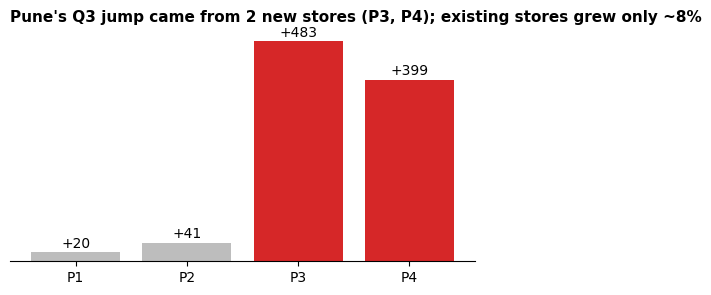

In [14]:
title = "Pune's Q3 jump came from 2 new stores (P3, P4); existing stores grew only ~8%"

change = by_store[3] - by_store[2]
colors = ["#bdbdbd" if s in ("P1", "P2") else "#d62728" for s in by_store.index]
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(change.index, change.values, color=colors)
for x, v in zip(change.index, change.values):
    ax.text(x, v + 10, f"{v:+d}", ha="center")
ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_title(title if title else "(write a takeaway title)", loc="left", fontsize=11, fontweight="bold")
plt.show()

### 5b · "Partner B is more punctual, send everything to B" (insight 5)

In [15]:
overall = df.groupby("delivery_partner")["on_time"].mean().mul(100).round(1)
mix = (pd.crosstab(df["delivery_partner"], df["zone"], normalize="index") * 100).round(0)
print("Overall on-time %:\n", overall, "\n\nShare of each partner's orders by zone (%):\n", mix)

by_zone = (df.groupby(["zone", "delivery_partner"])["on_time"].mean() * 100).round(1).unstack()
better_in_every_zone = 'Partner A'
phenomenon = "Simpson's paradox"

if ready(by_zone, better_in_every_zone, phenomenon):
    display(by_zone)
    print(f"Better inside every zone: {better_in_every_zone} | effect: {phenomenon}")

Overall on-time %:
 delivery_partner
Partner A    87.1
Partner B    93.0
Name: on_time, dtype: float64 

Share of each partner's orders by zone (%):
 zone              Suburban  Urban
delivery_partner                 
Partner A             67.0   33.0
Partner B             16.0   84.0


delivery_partner,Partner A,Partner B
zone,,
Suburban,81.4,72.0
Urban,98.8,96.9


Better inside every zone: Partner A | effect: Simpson's paradox


**✏️ Your answer (Part 5):** (a) Rewrite insight 3 so it is honest. (b) Explain in plain language why Partner B *looks* better overall, and what question a careful human asks before accepting a comparison like insight 5.

*Your answer:*

**(a)** *"Pune orders rose 117% from Q2 to Q3, but almost all of that came from two new stores (P3 and P4) that opened in Q3 and added 882 orders. Like-for-like, the two existing stores (P1, P2) grew 7.6% (803 → 864 orders). The expansion added volume; whether it is a 'success' depends on the new stores' costs and on whether they took orders from P1 and P2, which this data cannot show yet."*

**(b)** Partner B's orders are mostly urban (84%), and urban deliveries are short and easy (about 97–99% on time). Partner A does most of the hard suburban deliveries (67% of its orders), where on-time is much lower. When you look *inside* each zone, **Partner A is better in both** (Urban 98.8% vs 96.9%; Suburban 81.4% vs 72.0%). B only looks better overall because it gets the easier jobs. This is **Simpson's paradox**. Routing everything to B would probably *lower* on-time performance, especially in the suburbs. A careful human asks: *"Are the two groups being compared on the same mix of cases? What confounder, such as zone or distance, differs between them? Does the result hold within each subgroup?"*

---
## Part 6 · Triage the whole report

For each AI insight decide: **Accept** (correct as stated), **Correct** (the finding is useful but the wording or number must change) or **Reject** (not supported). Then measure the AI.

In [16]:
decisions = {
    1: "Accept",    # Bengaluru trend: slope +56/month, Kendall tau 0.89, p < 0.001
    2: "Correct",   # mean is right (₹465) but skew 13 -> report the median ₹358
    3: "Correct",   # +117% is mostly 2 new stores; like-for-like only +7.6%
    4: "Reject",    # drop is mainly a data gap at H2; on-time barely moved
    5: "Reject",    # Simpson's paradox: Partner A is better in both zones
    6: "Accept",    # r = -0.32 among rated orders, non-causal wording (caveat: ratings missing unevenly)
    7: "Accept",    # r = 0.38 and basket size rises steadily with discount; 'move together' is not causal
    8: "Accept",    # 26.1 vs 20.8 min -> about 5 min longer (checked below)
    9: "Reject",    # no model or evidence; Sept 'drop' itself is largely an artefact
}
print(df.groupby("zone")["delivery_minutes"].mean().round(1))
analysts_true_insights = 7    # true insights an expert team found in this data (given)

accepted = sum(v == "Accept" for v in decisions.values())   # = 4
if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    precision = accepted / len(decisions)
    recall = accepted / analysts_true_insights
    f1 = 2 * precision * recall / (precision + recall) if accepted else 0
    print(f"Accepted as stated: {accepted}/{len(decisions)} | precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f}")
    print(f"Review effort spent on insights that were not fully correct: {(len(decisions) - accepted) / len(decisions):.0%}")
else:
    print("⚠ Fill in all nine decisions with 'Accept', 'Correct' or 'Reject'.")

zone
Suburban    26.1
Urban       20.8
Name: delivery_minutes, dtype: float64
Accepted as stated: 4/9 | precision = 0.44 | recall = 0.57 | F1 = 0.50
Review effort spent on insights that were not fully correct: 56%


**✏️ Your answer (Part 6):** Using precision and recall, would you describe this AI as an *assistant* or a *replacement* for the analyst? Justify in two sentences.

*Your answer:*

**An assistant, not a replacement.** Only 4 of 9 insights could be accepted as written (precision 0.44), and they cover only 4 of the 7 true insights experts found (recall 0.57, F1 = 0.50). The errors were also the high-stakes ones (a causal claim about Hyderabad, a routing decision based on Simpson's paradox, an unsupported forecast), so more than half of the review effort (56%) went into fixing or rejecting claims. Every output needs a human check before Meera presents it.

---
## Part 7 · Communicating, steering and validating

### 7a · Three kinds of reading
Each insight reads the data at a different level: **`data`** (restates what is plotted), **`between`** (relationships or patterns) or **`beyond`** (predictions and causal explanations; the risk zone).

In [17]:
levels = {
    2: 'data',      # "The average order value is ₹465."
    6: 'between',   # "Longer delivery times go with lower ratings."
    9: 'beyond',    # "Orders will recover in October."
}      # levels: 'data', 'between' or 'beyond'
print(levels)

{2: 'data', 6: 'between', 9: 'beyond'}


### 7b · Steering the assistant (interactive refinement)
Match each thing Meera types to the kind of feedback it is: **Reject**, **Constrain**, **Steer**, **Adjust** or **Pin**.

In [18]:
user_actions = {
    '"Never use pie charts in this report"': 'Constrain',
    '"Use 5-minute bins for delivery time"': 'Adjust',
    '"Focus on on-time rate by city"': 'Steer',
    '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',
    '"Not this chart again"': 'Reject',
}   # feedback types: 'Reject', 'Constrain', 'Steer', 'Adjust', 'Pin'
user_actions

{'"Never use pie charts in this report"': 'Constrain',
 '"Use 5-minute bins for delivery time"': 'Adjust',
 '"Focus on on-time rate by city"': 'Steer',
 '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',
 '"Not this chart again"': 'Reject'}

### 7c · Which validation threat?
Meera now says: *"My real worry is why **repeat customers** are leaving. The AI answered a different question: how orders changed."* The AI's numbers were all computed correctly.

In [19]:
threat = 'wrong problem'   # correct numbers, but they answer a question Meera did not ask (repeat-customer churn)
threat

'wrong problem'

**✏️ Your answer (Part 7):** Rewrite insight 2 *and* insight 4 as statements you would be comfortable presenting. Each rewrite should use the right measure or the right scope, avoid causal language the data cannot support, and be specific (no "interesting variation").

*Your answer:*

**Insight 2 (rewritten):** *"From January to September, the typical (median) FreshKart order was ₹358. Half of orders were below this. The mean is higher (₹465) because a small number of very large orders pull it up, so we use the median as the headline figure. (Computed after removing 70 duplicate rows.)"*

**Insight 4 (rewritten):** *"Hyderabad's recorded orders fell from 483 in August to 346 in September (−28%). Most of the fall is explained by missing data: store H2 has no order records between 5 and 25 September. Over the same period Hyderabad's on-time rate was steady (89.0% → 88.7%) and discounts were unchanged (about 9.4%), so the data do not show a decline in service. Excluding H2, stores H1 and H3 averaged 9.8 orders/day in September against 10.5 in August, which is within their normal range. Next step: confirm with operations whether H2 was closed or its data feed failed."*

---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which AI insight did you find most convincing? What made it convincing (the number, the tone, the chart, the confident wording), and would you have caught the problem without the checks?



Insight 5 (Partner B 93% vs 87%) was the most convincing at first: it had two precise percentages, a clear winner and a concrete action, which made it sound like a finished analysis. The confident wording and the specific numbers carried it. I would not have caught the Simpson's paradox without splitting by zone. The overall numbers are correct, so nothing looks wrong until you check the mix of zones each partner serves.

**2. Choosing the level of automation.** For FreshKart, name one task where you would let the AI work with little supervision and one where you would insist on a human check. What did you use to decide (stakes, reversibility, how visible errors are)?



Low supervision: routine descriptive work such as producing the monthly order counts, profiling the data (duplicates, missing values) or drafting chart code. These are cheap to check, easy to redo, and errors show up quickly. A human check is essential for anything causal or prescriptive that drives an operational decision, such as rerouting all orders to Partner B or explaining the Hyderabad drop to leadership. I decided by the stakes, how hard the decision is to reverse, and how invisible the error would be. A Simpson's-paradox error looks perfectly plausible on a slide.

**3. Making trust cheaper.** Pick one problem you found (e.g. the Hyderabad gap, the missing ratings, or Partner B). What should the AI tool have *shown* (code, sample size, data gaps, uncertainty) so you could verify it faster, and what control would you want (edit, undo, switch off)?



The Hyderabad gap. The tool should have shown rows per store per week, or a data-completeness warning ("H2: 0 records for 21 days"), together with the query or code behind the −28% and the sample size per store. Any causal explanation should have been labelled as a hypothesis with the test that would confirm it. I would want controls to drill down by store, edit or override the explanation, exclude a store and recompute, and switch off automatic causal narratives.

**4. Responsibility.** If Meera presents the corrected report and one number is still wrong, who is accountable, the AI, the tool's vendor, you or Meera? What would you do differently next time to carry that responsibility well?



Accountability stays with the humans. Meera owns what she presents, and I, as the analyst who signed it off, am accountable for its accuracy. The AI cannot be held accountable, and the vendor is responsible only for the tool working as documented. Next time I would keep a reproducible notebook for every number, have a second person spot-check the key figures, and state the assumptions and data caveats on the slide itself so any remaining error can be traced and corrected quickly.